# Notebook 01: Exploratory Data Analysis & Common Table Architecture
**Portfolio Project:** Lending Product Funnel & Approval Analysis  
**Institutional Framing:** Retail Lending Product Analyst at an Indian NBFC (e.g. Bajaj Finance)  
**Objective:** Inspect raw schemas, audit data missingness and selection bias, reconcile row counts (29.9M records), and establish the canonical common applications data model.


In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

con = duckdb.connect()
print("DuckDB engine initialized successfully.")


DuckDB engine initialized successfully.


## 1. Raw Schema Inspection & Column Alignment
The project processes two separate raw files in `data/raw/`:
1. `accepted_2007_to_2018Q4.csv.gz` (2,260,701 rows, 151 columns)
2. `rejected_2007_to_2018Q4.csv.gz` (27,648,741 rows, 9 columns)


In [2]:
# Inspect sample records from canonical Parquet mart
df_sample = con.execute("""
    SELECT 
        application_id, application_date, application_year, loan_amount,
        dti, dti_band, risk_score, has_risk_score, addr_state,
        emp_length_band, loan_purpose, is_approved, outcome_bucket
    FROM read_parquet('data/processed/common_applications.parquet')
    LIMIT 10;
""").df()

df_sample


,application_id,application_date,application_year,loan_amount,dti,dti_band,risk_score,has_risk_score,addr_state,emp_length_band,loan_purpose,is_approved,outcome_bucket
0,ACC_67115563,2015-12-01,2015,26500.0,24.77,20-30%,667.0,1,TX,10+ years,debt_consolidation,1,Charged Off
1,ACC_66484220,2015-12-01,2015,28000.0,7.69,0-10%,717.0,1,IL,10+ years,credit_card,1,Fully Paid
2,ACC_65717516,2015-12-01,2015,16550.0,28.78,20-30%,717.0,1,FL,10+ years,debt_consolidation,1,Charged Off
3,ACC_67195550,2015-12-01,2015,18000.0,22.88,20-30%,682.0,1,PA,1-4 years,debt_consolidation,1,Fully Paid
4,ACC_66592057,2015-12-01,2015,9000.0,15.49,10-20%,687.0,1,VA,1-4 years,debt_consolidation,1,Fully Paid
5,ACC_67015457,2015-12-01,2015,33600.0,13.50,10-20%,682.0,1,GA,10+ years,debt_consolidation,1,Current
6,ACC_67205237,2015-12-01,2015,15000.0,16.75,10-20%,682.0,1,OK,5-9 years,debt_consolidation,1,Fully Paid
7,ACC_67125439,2015-12-01,2015,13000.0,32.33,30-40%,722.0,1,OH,10+ years,credit_card,1,Charged Off
8,ACC_67115505,2015-12-01,2015,8000.0,30.93,30-40%,667.0,1,MI,10+ years,debt_consolidation,1,Fully Paid
9,ACC_67125535,2015-12-01,2015,4600.0,10.70,10-20%,662.0,1,GA,1-4 years,credit_card,1,Charged Off


## 2. Row Count Reconciliation Audit
Every row from the raw files is accounted for:
- Raw Accepted: 2,260,701 records. Exactly 33 trailing footer/metadata rows where `issue_d` is null are dropped, leaving 2,260,668 valid funded loans.
- Raw Rejected: 27,648,741 records. Zero null dates, 100% retained.
- Total Canonical Applications: 29,909,409.


In [3]:
reconciliation_summary = con.execute("""
    SELECT 
        is_approved,
        CASE WHEN is_approved = 1 THEN 'Approved & Funded' ELSE 'Rejected' END AS status_label,
        count(*) AS total_records,
        round(count(*)::DOUBLE / 29909409.0 * 100, 2) AS pct_of_total_applications
    FROM read_parquet('data/processed/common_applications.parquet')
    GROUP BY is_approved;
""").df()

reconciliation_summary


,is_approved,status_label,total_records,pct_of_total_applications
0,0,Rejected,27648741,92.44
1,1,Approved & Funded,2260668,7.56


## 3. Critical Data Nuance: Missing Bureau Scores & Knockout Bias
Notice that in the rejected table, only 33.1% (9.15M records) have a recorded risk score. 
In institutional lending (Bajaj Finance), applicants failing initial knockout rules (e.g., negative DTI, unsupported postal code, self-reported zero income) are rejected before incurring external credit bureau inquiry costs.


In [4]:
risk_score_missingness = con.execute("""
    SELECT 
        CASE WHEN is_approved = 1 THEN 'Approved & Funded' ELSE 'Rejected' END AS application_status,
        count(*) AS total_applications,
        count(risk_score) AS scored_count,
        count(*) - count(risk_score) AS missing_score_count,
        round((count(*) - count(risk_score))::DOUBLE / count(*) * 100, 2) AS missing_score_pct
    FROM read_parquet('data/processed/common_applications.parquet')
    GROUP BY is_approved;
""").df()

risk_score_missingness


,application_status,total_applications,scored_count,missing_score_count,missing_score_pct
0,Rejected,27648741,9151111,18497630,66.9
1,Approved & Funded,2260668,2260668,0,0.0


## 4. Key Distributions Across Common Dimensions
Visualizing distribution of loan amounts, DTI bands, and employment tenure.


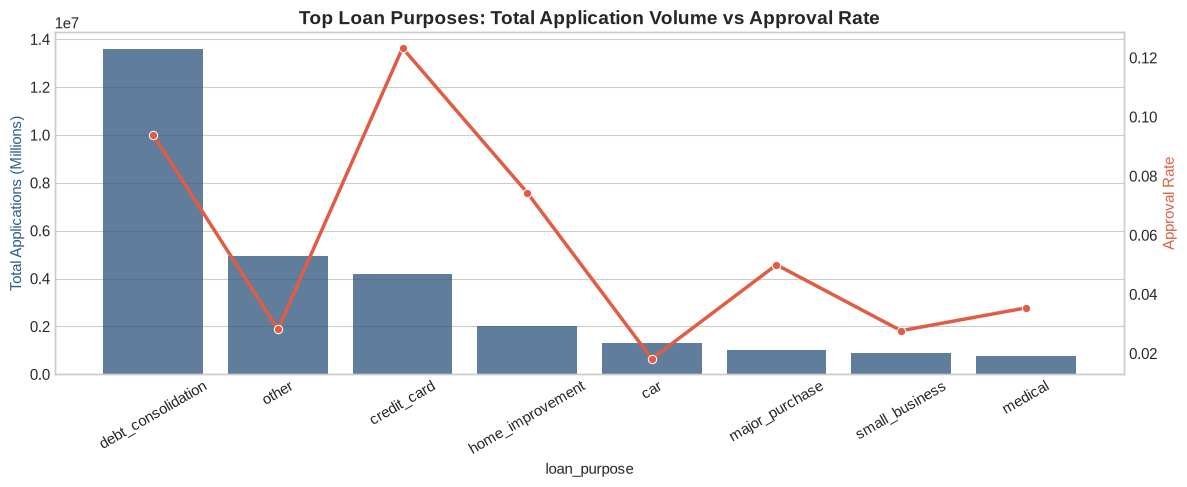

In [5]:
# Distribution of applied volume by loan purpose
df_purpose = con.execute("""
    SELECT 
        loan_purpose,
        count(*) AS total_applied,
        count(CASE WHEN is_approved = 1 THEN 1 END) AS approved_count,
        round(count(CASE WHEN is_approved = 1 THEN 1 END)::DOUBLE / count(*), 4) AS approval_rate
    FROM read_parquet('data/processed/common_applications.parquet')
    GROUP BY loan_purpose
    ORDER BY total_applied DESC
    LIMIT 8;
""").df()

fig, ax1 = plt.subplots(figsize=(12, 5))
sns.barplot(data=df_purpose, x='loan_purpose', y='total_applied', ax=ax1, color='#2b5c8f', alpha=0.8)
ax1.set_ylabel('Total Applications (Millions)', color='#2b5c8f')
ax1.set_title('Top Loan Purposes: Total Application Volume vs Approval Rate', fontsize=14, fontweight='bold')
ax1.tick_params(axis='x', rotation=30)

ax2 = ax1.twinx()
sns.lineplot(data=df_purpose, x='loan_purpose', y='approval_rate', ax=ax2, color='#e05d44', marker='o', linewidth=2.5)
ax2.set_ylabel('Approval Rate', color='#e05d44')
ax2.grid(False)

plt.tight_layout()
plt.show()


## 5. Analytical Takeaways from EDA
1. **Underwriting Bottleneck:** The primary volume drop-off occurs between Stage 1 (Applied) and Stage 2 (Funded), with an overall pass-through rate of only 7.56%.
2. **Missingness is an Informative Signal:** Missing risk scores are concentrated entirely in rejected applications, confirming that Lending Club implemented a two-stage knockout funnel.
3. **Data Parity:** With 29,909,409 reconciled records, the canonical parquet table is ready for deep statistical and econometric analysis in Notebook 02.
